# Exercise 2 ? CNN baseline

Train a compact CNN on CIFAR-10. A fixed seed splits the official 50,000-image training set into 45,000 training and 5,000 validation examples. The original 10,000-image test set is held back until final evaluation. This notebook contains the completed training outputs; the recorded metrics and plots are saved in `artifacts/exercise_2/`.


## Why CNNs for image classification?
Images have local spatial structure: nearby pixels form edges, textures, and object parts. Convolutional filters learn reusable local patterns across image locations, and pooling reduces spatial size while providing some tolerance to shifts. An MLP flattens the image and uses dense connections, so it does not directly preserve neighborhoods and must learn spatial structure from examples. CNN weight sharing gives a useful image bias with fewer parameters.


## 1. Setup and reproducibility
Works when Jupyter starts from the project root or this notebook directory.

In [1]:
import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks": PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_2"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda": print(torch.cuda.get_device_name(0))


Device: cuda
NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Dataset and fixed train/validation split
`download=False` prevents a notebook run from unexpectedly downloading data. The seeded permutation uses only the official training set; the test set is loaded separately and held aside.

In [2]:
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
train_val = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=transform)
assert len(train_val) == 50_000
indices = torch.randperm(50_000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_dataset, val_dataset = Subset(train_val, indices[:45_000]), Subset(train_val, indices[45_000:])
print(f"Train: {len(train_dataset):,}; validation: {len(val_dataset):,}; official test remains reserved for final evaluation.")
print("Classes:", train_val.classes)

BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
loader_args = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=(DEVICE.type == "cuda"))
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)


Train: 45,000; validation: 5,000; official test remains reserved for final evaluation.
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. CNN architecture
Two convolutions (3→32 and 32→64) each use ReLU and 2×2 max pooling. A 32×32 image becomes 8×8 after pooling; the only dense layer maps `64×8×8` to 10 classes. This is exactly three trainable layers.

In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * 8 * 8, 10)
    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        return self.fc(self.flatten(x))

model = CIFAR10CNN().to(DEVICE)
trainable_layers = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
assert len(trainable_layers) == 3
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Trainable layers:", len(trainable_layers), "| trainable parameters:", f"{parameter_count:,}")


CIFAR10CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable layers: 3 | trainable parameters: 60,362


## 4. Training and validation
CrossEntropyLoss and Adam are used. Each epoch records sample-weighted loss and accuracy for both training and validation. The test loader is not used here.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {k: [] for k in ("train_loss", "val_loss", "train_accuracy", "val_accuracy")}
def epoch_metrics(loader, training):
    model.train(training); loss_sum = correct = count = 0
    with (torch.enable_grad() if training else torch.no_grad()):
        for x, y in tqdm(loader, leave=False):
            try:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                if training: optimizer.zero_grad(set_to_none=True)
                logits = model(x); loss = criterion(logits, y)
                if training: loss.backward(); optimizer.step()
                n = y.size(0); count += n; loss_sum += loss.item() * n
                correct += (logits.argmax(1) == y).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                # Do not retry; start over with a smaller batch and newly initialized model and optimizer.
                optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA out of memory. Training has stopped without retrying. "
                    "Reduce BATCH_SIZE, recreate the model and optimizer, and restart training from the beginning."
                ) from exc
    return loss_sum / count, correct / count
for epoch in range(1, EPOCHS + 1):
    tl, ta = epoch_metrics(train_loader, True)
    vl, va = epoch_metrics(val_loader, False)
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {tl:.4f}, acc {ta:.4f} | val loss {vl:.4f}, acc {va:.4f}")


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/20 | train loss 1.3240, acc 0.5326 | val loss 1.1065, acc 0.6176


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 2/20 | train loss 0.9820, acc 0.6624 | val loss 0.9688, acc 0.6640


... (50 outputs left out)

Epoch 19/20 | train loss 0.2687, acc 0.9046 | val loss 1.2705, acc 0.6948


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.2559, acc 0.9089 | val loss 1.4142, acc 0.6798


## 5. Learning curves

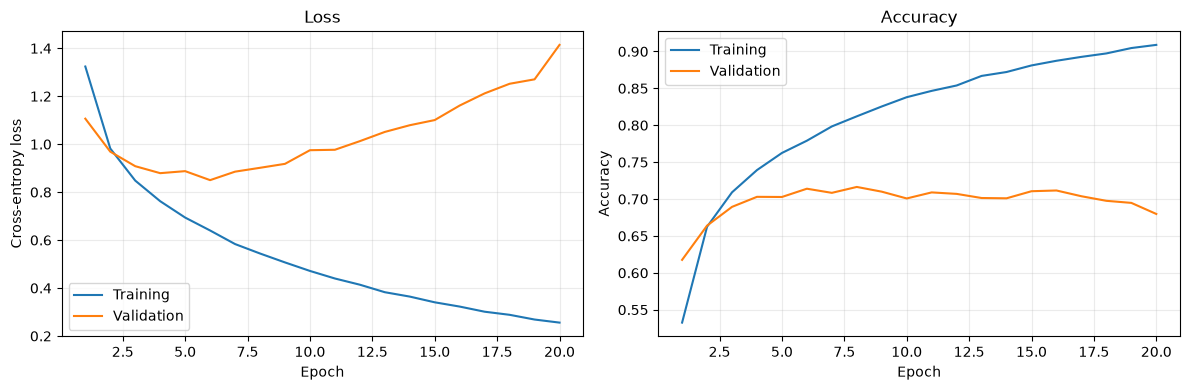

In [5]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["train_loss"], label="Training"); ax[0].plot(ep, history["val_loss"], label="Validation")
ax[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss"); ax[0].legend(); ax[0].grid(alpha=.25)
ax[1].plot(ep, history["train_accuracy"], label="Training"); ax[1].plot(ep, history["val_accuracy"], label="Validation")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160); plt.show()


## 6. Final evaluation on the untouched official test set
Evaluate only after training and do not use these results for tuning or model selection.

Official test:   0%|          | 0/157 [00:00<?, ?it/s]

Official test accuracy: 0.6850 (68.50%)
              precision    recall  f1-score   support

    airplane       0.73      0.72      0.72      1000
  automobile       0.83      0.77      0.80      1000
        bird       0.61      0.56      0.58      1000
         cat       0.43      0.61      0.50      1000
        deer       0.58      0.72      0.64      1000
         dog       0.62      0.54      0.58      1000
        frog       0.84      0.65      0.73      1000
       horse       0.78      0.71      0.75      1000
        ship       0.82      0.79      0.80      1000
       truck       0.78      0.78      0.78      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000



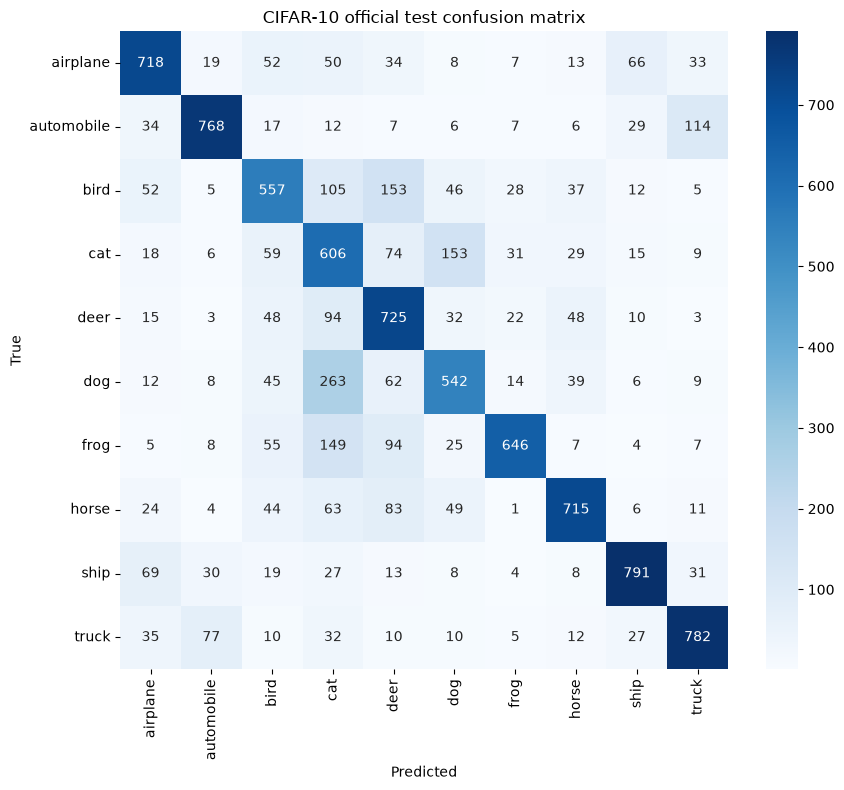

In [6]:
test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=transform)
assert len(test_dataset) == 10_000
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
model.eval(); y_true, y_pred = [], []
with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Official test"):
        pred = model(x.to(DEVICE, non_blocking=True)).argmax(1).cpu().tolist()
        y_pred.extend(pred); y_true.extend(y.tolist())
test_accuracy = float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
report_text = classification_report(y_true, y_pred, target_names=test_dataset.classes, zero_division=0)
report = classification_report(y_true, y_pred, target_names=test_dataset.classes, output_dict=True, zero_division=0)
print(f"Official test accuracy: {test_accuracy:.4f} ({100*test_accuracy:.2f}%)")
print(report_text)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=test_dataset.classes, yticklabels=test_dataset.classes, ax=ax)
ax.set(xlabel="Predicted", ylabel="True", title="CIFAR-10 official test confusion matrix"); fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "test_confusion_matrix.png", dpi=160); plt.show()
pd.DataFrame(cm, index=test_dataset.classes, columns=test_dataset.classes).to_csv(ARTIFACT_DIR / "test_confusion_matrix.csv", index_label="true_label")
with (ARTIFACT_DIR / "classification_report.json").open("w", encoding="utf-8") as f: json.dump(report, f, indent=2)


## 7. Save model and run results
The trained final-epoch model and measured metrics are saved in `artifacts/exercise_2/`. The checkpoint contains the final epoch weights; it is not a best-validation checkpoint.


In [7]:
torch.save({"model_state_dict": model.cpu().state_dict(), "seed": SEED, "class_names": train_val.classes}, ARTIFACT_DIR / "cnn_baseline.pth")
model.to(DEVICE)
results = {"seed": SEED, "device": str(DEVICE), "trainable_layers": len(trainable_layers), "trainable_parameters": parameter_count,
           "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
           "split_sizes": {"train": len(train_dataset), "validation": len(val_dataset), "official_test": len(test_dataset)},
           "history": history, "official_test_accuracy": test_accuracy}
with (ARTIFACT_DIR / "results.json").open("w", encoding="utf-8") as f: json.dump(results, f, indent=2)
print("Saved weights and results to", ARTIFACT_DIR)


Saved weights and results to D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_2
